# 01 Data: pull, profile and build the model table

- What it does: downloads Boston's food establishment inspections once, profiles them, and builds one row per routine inspection with leak-free history features.
- Inputs: the Analyze Boston CKAN API (or the saved snapshot `data/raw/inspections_snapshot.parquet`).
- Outputs: `data/raw/inspections_snapshot.parquet`, `data/raw/pull_metadata.json`, `data/processed/inspections_full.parquet`, `data/processed/model_table.parquet`, `results/figures/reinspection_gap.png`.

In [1]:
import sys
sys.path.insert(0, "..")          # so `from src import ...` works when run from notebooks/

import json
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.data_pull import pull_inspections
from src import features as F

SEED = 42
np.random.seed(SEED)
pd.set_option("display.width", 160)

## 1. Pull the data once

The pull selects only the columns we need and never requests the owner-name columns.
If the snapshot file already exists, the pull is skipped. Set `FORCE_PULL = True` to refresh it.

In [2]:
FORCE_PULL = False
raw = pull_inspections(raw_dir="../data/raw", force=FORCE_PULL)
print(json.dumps(json.load(open("../data/raw/pull_metadata.json")), indent=2)[:600])

Snapshot found, skipping the pull: ../data/raw/inspections_snapshot.parquet
{
  "pulled_at_utc": "2026-11-11T21:16:38+00:00",
  "api_url": "https://data.boston.gov/api/3/action/datastore_search_sql",
  "resource_id": "4582bec6-2b4f-4f9e-bc55-cbaa73117f4c",
  "sql": "SELECT \"_id\", \"licenseno\", \"businessname\", \"descript\", \"licstatus\", \"result\", \"resultdttm\", \"viol_level\", \"viol_status\", \"violdesc\", \"comments\", \"issdttm\", \"zip\", \"city\" FROM \"4582bec6-2b4f-4f9e-bc55-cbaa73117f4c\" WHERE \"resultdttm\" >= '2016-01-01' AND \"descript\" LIKE 'Eating & Drinking%' ORDER BY \"_id\" LIMIT <page> OFFSET <n>",
  "row_count": 444574,
  "columns": [
    


## 2. Profile the raw snapshot

The raw table has one row per violation, so one inspection can span many rows.

In [3]:
print("shape:", raw.shape)
print("unique licenses:", raw["licenseno"].nunique())
for col in ["result", "descript", "viol_level", "viol_status"]:
    print(f"\n{col}:")
    print(raw[col].value_counts(dropna=False).to_string())

shape: (444574, 14)
unique licenses: 6729

result:
result
HE_Fail       188093
HE_Pass       145000
HE_FailExt     41273
HE_Filed       39266
HE_Hearing     12707
HE_NotReq      11831
HE_VolClos      2848
HE_TSOP         2455
HE_OutBus        583
HE_Closure       403
HE_FAILNOR        70
HE_Misc           41
Closed             2
Pass               1
NoViol             1

descript:
descript
Eating & Drinking                255445
Eating & Drinking w/ Take Out    189129

viol_level:
viol_level
*      270581
**      83217
***     56511
NaN     34265

viol_status:
viol_status
Fail    227537
Pass    188986
NaN      28051


In [4]:
raw_date = pd.to_datetime(raw["resultdttm"].str.slice(0, 19))
print("data runs from", raw_date.min().date(), "to", raw_date.max().date())

per_year = pd.DataFrame({
    "violation_rows": raw.groupby(raw_date.dt.year).size(),
    "inspections": raw.assign(d=raw_date.dt.date).drop_duplicates(["licenseno", "d"]).groupby(raw_date.dt.year).size(),
})
print(per_year.to_string())

has_comment = raw["comments"].fillna("").str.strip().ne("")
print(f"\ncomment coverage: {has_comment.mean():.1%} of rows, "
      f"{has_comment.groupby([raw['licenseno'], raw_date.dt.date]).any().mean():.1%} of inspections")

data runs from 2016-01-02 to 2026-11-10
            violation_rows  inspections
resultdttm                             
2016                 47474         8955
2017                 37991         8183
2018                 45346         8680
2019                 39528         8520
2020                 27560         6608
2021                 39371         9408
2022                 49868        15996
2023                 36925        11402
2024                 42214        12446
2025                 39482        10575
2026                 38815         9706



comment coverage: 93.2% of rows, 75.1% of inspections


### What the profile tells us (logged in `docs/DECISIONS.md`)

- Fail codes: `HE_Fail`, `HE_FailExt`, `HE_Hearing`, `HE_TSOP`, `HE_Closure`, `HE_VolClos`, `HE_FAILNOR`.
- Pass codes: `HE_Pass`, `HE_Filed` (violations noted, no follow-up required), plus the rare `Pass` and `NoViol`.
- Administrative, dropped: `HE_NotReq`, `HE_OutBus`, `HE_Misc`, `Closed`. These are not inspections.
- One inspection = one license number on one calendar date.
- 2020 has fewer inspections (the pandemic). We keep it.
- `viol_status` is `Fail` when a violation is found and `Pass` when an earlier violation is re-checked and found corrected, so "violations found" counts only the `Fail` rows.

## 3. Build the model table

`build_model_table` runs the steps in a fixed order: clean, one row per inspection, history features on the full sequence, drop re-inspections, split by year.
History features are computed **before** re-inspections are dropped, so they describe everything ISD knew at the time.

In [5]:
table, full = F.build_model_table(raw)

clean: dropped 0 rows missing a license or date
clean: dropped 12,457 administrative rows (Closed, HE_Misc, HE_NotReq, HE_OutBus)


clean: masked personal info in 1,124 of 191,948 distinct comments


collapse: 98,907 inspections; 241 had both a fail and a pass code on the same day (labelled fail)


re-inspections dropped: 40,304 of 98,907 (40.7%); model table has 58,603 rows


In [6]:
print(f"fail rate, all inspections (incl. re-inspections): {full['label_fail'].mean():.1%}")
print(f"fail rate, routine inspections (model table):      {table['label_fail'].mean():.1%}")
print("\nfail rate per year (model table):")
print(table.groupby("year")["label_fail"].agg(rows="size", fail_rate="mean").round(3).to_string())

fail rate, all inspections (incl. re-inspections): 43.0%
fail rate, routine inspections (model table):      59.3%

fail rate per year (model table):
      rows  fail_rate
year                 
2016  4983      0.669
2017  4909      0.589
2018  5144      0.620
2019  5179      0.582
2020  3876      0.554
2021  5755      0.559
2022  6069      0.614
2023  5520      0.558
2024  5652      0.595
2025  6184      0.562
2026  5332      0.618


## 4. Re-inspections

After a failed inspection, ISD returns to check that the violations were fixed. Those follow-up visits are not the decision we want to support (ISD has to make them anyway), so we drop them.
The plot shows how soon the next visit comes after a failure.

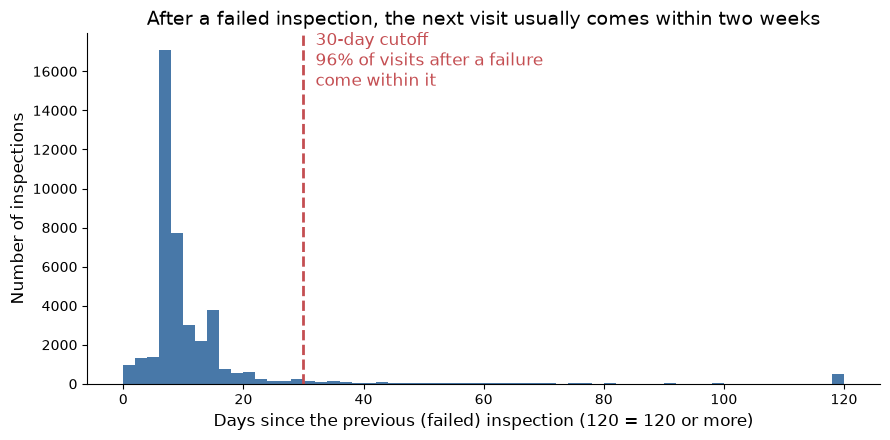

median gap after a failure: 8 days
re-inspections dropped: 40,304 of 98,907 inspections


In [7]:
after_fail = full.loc[full["last_fail"] == 1, "days_since_last"]
share_within = (after_fail <= F.REINSPECTION_DAYS).mean()

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist(after_fail.clip(upper=120), bins=range(0, 122, 2), color="#4878a8")
ax.axvline(F.REINSPECTION_DAYS, color="#c44e52", linestyle="--", linewidth=2)
ax.text(F.REINSPECTION_DAYS + 2, ax.get_ylim()[1] * 0.85,
        f"{F.REINSPECTION_DAYS}-day cutoff\n{share_within:.0%} of visits after a failure\ncome within it",
        color="#c44e52", fontsize=12)
ax.set_title("After a failed inspection, the next visit usually comes within two weeks", fontsize=14)
ax.set_xlabel("Days since the previous (failed) inspection (120 = 120 or more)", fontsize=12)
ax.set_ylabel("Number of inspections", fontsize=12)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig("../results/figures/reinspection_gap.png", dpi=150)
plt.show()

print(f"median gap after a failure: {after_fail.median():.0f} days")
print(f"re-inspections dropped: {int(full['is_reinspection'].sum()):,} of {len(full):,} inspections")

## 5. Privacy checks

The repo is public, so no owner names may be saved. The pull never requested them. Inspectors sometimes write a person's name, an email or a phone number in the comments, and `clean()` masks those with `[NAME]`, `[EMAIL]` and `[PHONE]`.

In [8]:
assert not F.OWNER_COLUMNS & set(raw.columns), "owner columns in the raw snapshot"
assert not F.OWNER_COLUMNS & set(table.columns), "owner columns in the model table"

honorific = re.compile(r"\b(?:Mr|Mrs|Ms)\.\s*[A-Z]")
email = re.compile(r"[\w.\-]+@[\w\-]+\.\w+")
for name, series in [("raw comments", raw["comments"].dropna().drop_duplicates()),
                     ("model table comments", pd.concat([full["comments"], full["prior_comments"]]).drop_duplicates())]:
    print(f"{name}: {series.str.contains(honorific).sum()} with Mr./Mrs./Ms., "
          f"{series.str.contains(email).sum()} with an email address")

masked = pd.concat([full["comments"]]).drop_duplicates()
print("comments containing a mask after cleaning:",
      {tag: int(masked.str.contains(tag, regex=False).sum()) for tag in ["[NAME]", "[EMAIL]", "[PHONE]"]})

raw comments: 3 with Mr./Mrs./Ms., 956 with an email address


model table comments: 0 with Mr./Mrs./Ms., 0 with an email address
comments containing a mask after cleaning: {'[NAME]': 180, '[EMAIL]': 1217, '[PHONE]': 88}


## 6. Split and leakage checks

The split is fixed by calendar year: train 2016 to 2022, validation 2023, test 2024 onward.

In [9]:
print(table.groupby("split").agg(rows=("label_fail", "size"), fail_rate=("label_fail", "mean"),
                                 first_day=("date", "min"), last_day=("date", "max")).loc[["train", "val", "test"]].to_string())

# Every date must sit inside its split.
assert table.loc[table["split"] == "train", "year"].between(2016, 2022).all()
assert (table.loc[table["split"] == "val", "year"] == 2023).all()
assert (table.loc[table["split"] == "test", "year"] >= 2024).all()

        rows  fail_rate  first_day   last_day
split                                        
train  35915   0.599137 2016-01-02 2022-12-30
val     5520   0.557609 2023-01-03 2023-12-29
test   17168   0.589993 2024-01-02 2026-11-10


In [10]:
# For 3 random restaurants: prior_n is the row position, last_fail is the previous label,
# prior_comments is the previous inspection's comments.
F.check_no_leakage(full, n_restaurants=3, seed=SEED)

  license 612204: 5 inspections, history features only use earlier rows  OK
  license 18497: 15 inspections, history features only use earlier rows  OK
  license 547959: 13 inspections, history features only use earlier rows  OK


## 7. Save

In [11]:
full.to_parquet("../data/processed/inspections_full.parquet", index=False)   # full sequence, used for the priority list
table.to_parquet("../data/processed/model_table.parquet", index=False)
print("saved model table:", table.shape)
print(table[["inspection_id", "date", "label_fail", "prior_n", "prior_fail_rate", "last_fail",
             "days_since_last", "license_age_days", "neighborhood", "split"]].head().to_string())

saved model table: (58603, 32)
     inspection_id       date  label_fail  prior_n  prior_fail_rate  last_fail  days_since_last  license_age_days neighborhood  split
0  112361_20161004 2016-10-04           0        0              NaN        NaN              NaN               925      Allston  train
1  112361_20180927 2018-09-27           1        1         0.000000        0.0            723.0              1648      Allston  train
2  112361_20191024 2019-10-24           0        3         0.333333        0.0            385.0              2040      Allston  train
3  112361_20201104 2020-11-04           0        4         0.250000        0.0            377.0              2417      Allston  train
4  112361_20210930 2021-09-30           1        5         0.200000        0.0            330.0              2747      Allston  train
